# Phase 1 · 03 · Preprocessing

**Goal:** pick the paper's features and define its normalization.

1. Remove `unassigned`, which is not a genus.
2. Find the exact prevalence rule behind the paper's 347 genera, using Table S3 as the answer key.
3. Define the normalization (log, then standardize) and work through it by hand.
4. Save the 347 raw features and the labels for Phase 2A.

The normalization is only defined here, not applied to the saved data. The paper learns it during model training, so Phase 2A learns it on the training part of each split.

## Setup

Inputs: the Zenodo abundance table, the sample list from notebook 02, and Table S3 from the paper's supplement (`papers/spreadsheets/mmc3.xlsx`). Outputs go to `data/processed/phase_1/03_preprocessing/`, `results/figures/phase_1/03_preprocessing/` and `results/tables/phase_1/03_preprocessing/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def find_project_root() -> Path:
    """Walk up from the current folder to the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("No requirements.txt above this folder.")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
RAW = PROJECT_ROOT / "data" / "raw" / "zenodo"
SHEETS = PROJECT_ROOT / "papers" / "spreadsheets"
BALANCED = PROJECT_ROOT / "data" / "processed" / "phase_1" / "02_balanced_subset"
PROCESSED = PROJECT_ROOT / "data" / "processed" / "phase_1" / "03_preprocessing"
FIGURES = PROJECT_ROOT / "results" / "figures" / "phase_1" / "03_preprocessing"
TABLES = PROJECT_ROOT / "results" / "tables" / "phase_1" / "03_preprocessing"
for folder in (PROCESSED, FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))


metadata = pd.read_csv(RAW / "Metadata.all.samples.tsv", sep="\t", index_col="Sample_ID", dtype={"Sample_ID": str})
relab = pd.read_csv(RAW / "Relab.all.samples.tsv", sep="\t", index_col=0).T.loc[metadata.index].rename_axis("Sample_ID")
balanced_samples = pd.read_csv(BALANCED / "balanced_samples.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
s3_genera = set(pd.read_excel(SHEETS / "mmc3.xlsx", sheet_name="ST3C")["Genera"].dropna())
print("all samples:", relab.shape, "  balanced samples:", len(balanced_samples), "  Table S3 genera:", len(s3_genera))

all samples: (8330, 3804)   balanced samples: 5966   Table S3 genera: 347


## 1. Remove `unassigned`

`unassigned` is the share of each sample's DNA that matched no known genus. It is a leftover, not a bacterium, so it is not a genus feature. Table S3 doesn't list it either.

In [2]:
assert "unassigned" not in s3_genera
relab = relab.drop(columns="unassigned")
print(f"{relab.shape[1]:,} genera left")

3,803 genera left


## 2. Which genera does the paper keep?

The paper's Methods keep features "present in 10% of all samples", and Table S3 lists the 347 genera that remained. Two details are open:
- **Which samples?** All 8,330, or only the 6,779 CRC and control samples.
- **Which cut?** More than 10%, or at least 10%.

We try all four readings and compare each with Table S3.

In [3]:
crc_ctr_ids = metadata.index[metadata["Condition"].isin(["CRC", "CTR"])]
sample_sets = {"all 8,330 samples": relab, "6,779 CRC and control samples": relab.loc[crc_ctr_ids]}

rows = []
for samples_name, samples in sample_sets.items():
    prevalence = (samples > 0).mean()
    for cut_name, kept in (("more than 10%", prevalence > 0.1), ("at least 10%", prevalence >= 0.1)):
        genera = set(prevalence.index[kept])
        rows.append({
            "samples": samples_name,
            "cut": cut_name,
            "genera kept": len(genera),
            "missing from S3": len(s3_genera - genera),
            "not in S3": len(genera - s3_genera),
        })

rule_table = pd.DataFrame(rows)
rule_table.to_csv(TABLES / "genus_filter_rules.csv", index=False)
rule_table

,samples,cut,genera kept,missing from S3,not in S3
0,"all 8,330 samples",more than 10%,347,0,0
1,"all 8,330 samples",at least 10%,348,0,1
2,"6,779 CRC and control samples",more than 10%,337,15,5
3,"6,779 CRC and control samples",at least 10%,337,15,5


Only one reading matches Table S3 name for name: **non-zero in more than 10% of all 8,330 samples.** That is the rule, and the model uses these 347 genera.

The list is computed once on all samples, the way the paper describes it. It uses no labels, only whether a genus is present.

In [4]:
prevalence = (relab > 0).mean()
genera_347 = sorted(prevalence.index[prevalence > 0.1])
assert set(genera_347) == s3_genera
print(f"{len(genera_347)} genera, identical to Table S3")

347 genera, identical to Table S3


## 3. Normalization: log, then standardize

Raw shares have two problems:
- They span many orders of magnitude. One genus might be 0.3 of a sample, another 0.00001. A logarithm puts them on a comparable scale.
- `log(0)` is undefined, so a tiny pseudocount of `1e-5` is added first. Every zero becomes `log10(1e-5) = -5`.

Then each genus is **standardized**: subtract its mean and divide by its spread, so every feature is centered on 0 with a similar range. The paper states the log with a 1e-5 pseudocount and the z-score. One small detail comes from the authors' code, because the text doesn't give it: the spread is the standard deviation **plus q**, where q is the 10th percentile of all genera's standard deviations. This keeps genera that barely vary from being blown up by dividing by a number near zero.

Normalization has two steps, kept separate:
- **fit** learns each genus's mean and spread from some data,
- **apply** uses those learned numbers on any data.

The paper normalizes test data "using frozen parameters learned during model training". So in Phase 2A, fit only ever sees training samples, and apply is used on the test samples with the training numbers.

In [5]:
PSEUDOCOUNT = 1e-5


def fit_log_std(relab: pd.DataFrame) -> tuple[pd.Series, pd.Series]:
    """Learn each genus's mean and spread (standard deviation + its 10th percentile) on the log scale."""
    logged = np.log10(relab + PSEUDOCOUNT)
    sd = logged.std(ddof=1)
    return logged.mean(), sd + np.quantile(sd, 0.1)


def apply_log_std(relab: pd.DataFrame, mean: pd.Series, spread: pd.Series) -> pd.DataFrame:
    """Log-transform and standardize with already learned numbers."""
    return (np.log10(relab + PSEUDOCOUNT) - mean) / spread

A three-sample example, small enough to follow by hand. Genus `g1` is 0, 0.5 and 0.2 in the three samples.

In [6]:
tiny = pd.DataFrame({"g1": [0.0, 0.5, 0.2], "g2": [0.1, 0.1, 0.0]}, index=["sample_1", "sample_2", "sample_3"])
tiny_mean, tiny_spread = fit_log_std(tiny)

print("after log10(x + 1e-5):")
print(np.log10(tiny + PSEUDOCOUNT).round(3), "\n")
print("learned mean:  ", tiny_mean.round(3).to_dict())
print("learned spread:", tiny_spread.round(3).to_dict(), "\n")
print("normalized:")
print(apply_log_std(tiny, tiny_mean, tiny_spread).round(3))

after log10(x + 1e-5):
             g1   g2
sample_1 -5.000 -1.0
sample_2 -0.301 -1.0
sample_3 -0.699 -5.0 

learned mean:   {'g1': -2.0, 'g2': -2.333}
learned spread: {'g1': 4.945, 'g2': 4.648} 

normalized:
             g1     g2
sample_1 -0.607  0.287
sample_2  0.344  0.287
sample_3  0.263 -0.574


What normalization does to one real genus, *Fusobacterium*. This figure fits on all balanced samples only to show the shape. The model never does that: it fits on training samples only.

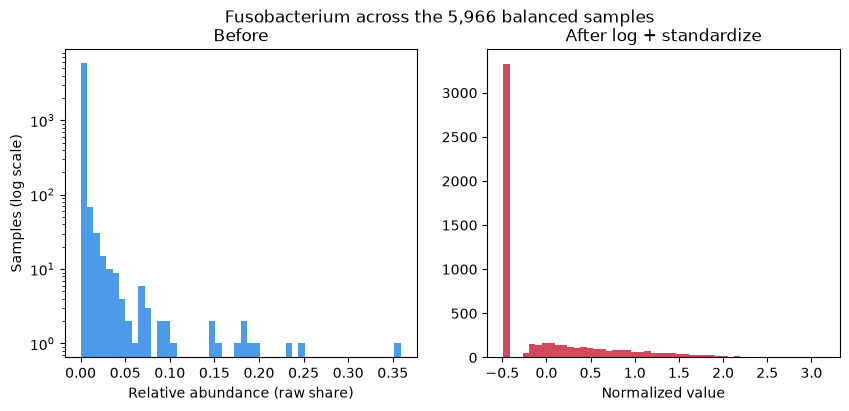

**Figure 1.** Fusobacterium is zero in 56% of the 5,966 samples, and its largest share is 0.359. Before normalizing, almost all samples sit in the first bar. After it, the values run from -0.49 to 3.14. All zeros land on the same value, -0.49, the tall bar on the left.

In [7]:
genus = "Fusobacterium"
balanced_347 = relab.loc[balanced_samples.index, genera_347]
mean, spread = fit_log_std(balanced_347)
normalized_values = apply_log_std(balanced_347, mean, spread)[genus]
raw_values = balanced_347[genus]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
left.hist(raw_values, bins=50, color="#4C9BE8")
left.set_yscale("log")
left.set_xlabel("Relative abundance (raw share)")
left.set_ylabel("Samples (log scale)")
left.set_title("Before")
right.hist(normalized_values, bins=50, color="#D1495B")
right.set_xlabel("Normalized value")
right.set_title("After log + standardize")
fig.suptitle(f"{genus} across the {len(raw_values):,} balanced samples")

show_figure(
    fig,
    "normalization_example",
    f"{genus} is zero in {(raw_values == 0).mean():.0%} of the {len(raw_values):,} samples, and its largest share is {raw_values.max():.3f}. "
    f"Before normalizing, almost all samples sit in the first bar. After it, the values run from {normalized_values.min():.2f} "
    f"to {normalized_values.max():.2f}. All zeros land on the same value, {normalized_values[raw_values == 0].iloc[0]:.2f}, the tall bar on the left.",
)

## 4. Save the outputs

- `relab_347.csv`: raw shares of the 347 genera for the 5,966 balanced samples. Not normalized, because Phase 2A learns the normalization on each training split.
- `labels.csv`: for each sample, its study, sequencing method and label (1 = CRC, 0 = control), in the same row order.

pandas writes every number with full precision, so reading the CSV back gives exactly the same values. The first check below proves it.

In [8]:
relab_347 = balanced_347
labels = balanced_samples[["Cohort", "Assay"]].copy()
labels["label"] = (balanced_samples["Condition"] == "CRC").astype(int)

relab_347.to_csv(PROCESSED / "relab_347.csv")
labels.to_csv(PROCESSED / "labels.csv")
print(f"Saved relab_347.csv {relab_347.shape} and labels.csv to {PROCESSED.relative_to(PROJECT_ROOT).as_posix()}/")

Saved relab_347.csv (5966, 347) and labels.csv to data/processed/phase_1/03_preprocessing/


## 5. Checks

In [9]:
reloaded = pd.read_csv(PROCESSED / "relab_347.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
assert reloaded.equals(relab_347), "the CSV must give back exactly the saved numbers"
assert relab_347.shape == (5966, 347)
assert relab_347.index.equals(labels.index)
assert len(labels) == 5966 and labels["label"].sum() == 2983

tiny_normalized = apply_log_std(tiny, tiny_mean, tiny_spread)
assert np.isfinite(tiny_normalized.to_numpy()).all()
assert np.allclose(tiny_normalized.mean(), 0)
print("All checks passed.")

All checks passed.


## What we learned

- `unassigned` is DNA matched to no genus, so it is removed. 3,803 genera remain.
- The paper's 347 genera come from one exact rule: non-zero in **more than** 10% of **all 8,330** samples. It reproduces Table S3 name for name, and the other three readings miss. The model uses these 347 genera.
- Normalization is log10 with a 1e-5 pseudocount, then standardization. The small floor added to each standard deviation comes from the authors' code, because the text doesn't give it.
- Fit and apply are separate. Phase 2A fits on training samples only and applies those frozen numbers to the test samples, as the paper describes.